In [1]:
import dataset_utils as du
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
hdf5_path="../../Data/lung_radiomics_datasets.hdf5"
df_metdata_path="../../Data/lung_radiomics_datasets_mod.csv"
df = du.dataframe_from_hdf5(hdf5_path)
sample = df.query("dataset == 'stanford' and modality == 'chest'").iloc[0]
patient_id = sample['patient_id']
modality = sample['modality']
dataset = sample['dataset']
slice_id = np.random.randint(0, sample['slices'])

In [4]:
df['patient_id'].unique().shape

(181,)

In [10]:
df_metadata = pd.read_csv(df_metdata_path)
df_metadata

,Unnamed: 0,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,b_mask,f_mask
0,0,AMC-001:1,AMC-001,stanford,Wildtype,0,pet,1,2,42,1,41
1,1,AMC-001:2,AMC-001,stanford,Wildtype,0,pet,2,2,42,1,41
2,2,AMC-001:3,AMC-001,stanford,Wildtype,0,pet,3,2,42,1,41
3,3,AMC-001:4,AMC-001,stanford,Wildtype,0,pet,4,2,42,1,41
4,4,AMC-001:5,AMC-001,stanford,Wildtype,0,pet,5,2,42,1,41
...,...,...,...,...,...,...,...,...,...,...,...,...
1869,1869,sm_034:1,sm_034,santa_maria,Wildtype,0,ct,1,13,18,1,17
1870,1870,sm_034:2,sm_034,santa_maria,Wildtype,0,ct,2,13,18,1,17
1871,1871,sm_034:3,sm_034,santa_maria,Wildtype,0,ct,3,13,18,1,17
1872,1872,sm_034:4,sm_034,santa_maria,Wildtype,0,ct,4,13,18,1,17


In [ ]:
# df_metadata
df_metadata.loc[df_metadata['dataset'] == 'stanford'].iloc[0]

Unnamed: 0                0
patient_id_new    AMC-001:1
patient_id          AMC-001
dataset            stanford
egfr               Wildtype
label                     0
modality                pet
begin                     1
divisor                   2
length                   42
b_mask                    1
f_mask                   41
Name: 0, dtype: object

In [16]:
img_raw, mask = du.get_image_mask(hdf5_path, patient_id, modality, slice_id)

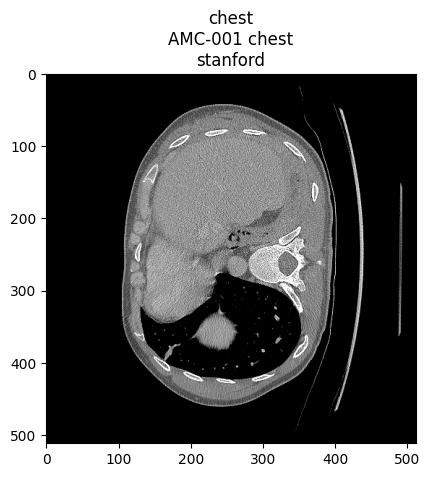

In [27]:
from skimage.segmentation import mark_boundaries
if modality == 'pet':
    img = du.percentile_window(img_raw, qmin=0, qmax=100)
else:
    img = du.apply_window_ct(img_raw, width=800, level=40)
    
img_mask = mark_boundaries(img, mask)
plt.imshow(img_mask)
plt.title(f'{modality}\n{patient_id} {modality}\n{dataset}')
plt.show()

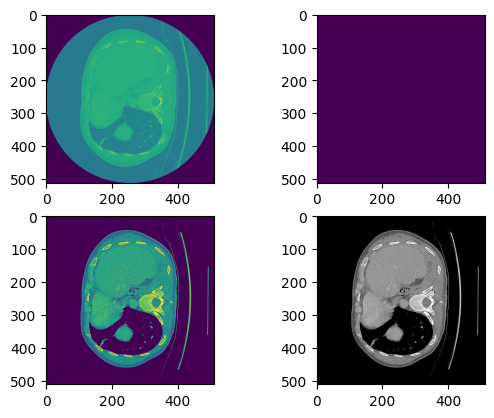

In [18]:
fig, axs = plt.subplots(2,2)
axs[0][0].imshow(img_raw)
axs[0][1].imshow(mask)
axs[1][0].imshow(img)
axs[1][1].imshow(img_mask)

In [48]:
import h5py
lala=h5py.File(hdf5_path, 'r')

In [57]:
lala['AMC-001_chest'].keys()

<KeysViewHDF5 ['egfr_label', 'hist_bins', 'hist_vals', 'img_exam', 'mask_exam', 'spatial_res']>

In [ ]:
parser = argparse.ArgumentParser(description="Obtener ViT patch embeddings de los dataset lung_radiomics")

parser.add_argument("-mn", "--model_name", type=str, default="smdino",
                    help="backbone ViT encoder medsam o smdino")
parser.add_argument("-mp", "--model_path", type=str,
                    default=os.path.join('models', 'backbones', 'smdino', 'model.pth'),
                    help="path del archivo model.pth")
parser.add_argument("-d", "--dataset_path", type=str, default=os.path.join('data', 'lung_radiomics'),
                    help="path de los datasets tfds santa_maria y stanford")
parser.add_argument("-f", "--feature_folder", type=str, default=os.path.join('data', 'features'),
                    help="carpeta de salida donde se guardaran los features")
parser.add_argument("-h5", "--hdf5_path", type=str, default=os.path.join('data', 'lung_radiomics', 'lung_radiomics_datasets.hdf5'),
                    help="path al dataset en formato HDF5 con imagenes isotropicas")
parser.add_argument("-df", "--df_path", type=str, default=os.path.join('data', 'lung_radiomics', 'lung_radiomics_datasets.csv'),
                    help="path a los metadatos del dataset")
parser.add_argument("-mod", "--modality", type=str, default='ct',
                    help="path a los metadatos del dataset")
parser.add_argument("-gpu", "--gpu_device", type=str, default='0', help="cuda device number")

In [20]:
second_modality="pet"
modalities = ['pet', second_modality] 
df_metadata = pd.read_csv("../Data/lung_radiomics_datasets.csv")
df_metadata['label']= (df_metadata['egfr'] == 'Mutant').astype(int)
patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
if second_modality == 'pet':
    df_metadata = df_metadata[np.logical_or(df_metadata['has_petct'], df_metadata['has_petchest'])]
else:
    df_metadata = df_metadata[df_metadata[f'has_{"".join(modalities)}']]
df_metadata.reset_index(inplace=True, drop=True)
df_metadata

,patient_id,dataset,has_egfr,ct_segmentation,ct_image,pet_image,egfr,pet_segmentation,chest_segmentation,chest_image,has_petct,has_petchest,has_ct_or_chest,has_ct_and_chest,label
0,AMC-001,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
1,AMC-006,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
2,AMC-011,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
3,AMC-012,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
4,AMC-013,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,sm_030,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
177,sm_031,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
178,sm_032,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
179,sm_033,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0


In [32]:
ls src

avg_kfold_metrics.py         split_patients.py
config_manager.py            tfds_dense_descriptor.py
MedSAM/                      train_models.py
merge_dataframe_features.py  visualization_utils.py
models_archs.py              visualize_features.py
__pycache__/                 visualize_point_clouds.py


In [9]:
def find_divisor(slice_count, modality):
    if modality == 'ct' or modality == 'chest':
        desired_slices = 13
    else:
        desired_slices = 2
    return np.clip(desired_slices, 1, slice_count)

def prepare_df(df, modality_a='pet', modality_b='ct'):
    df['divisor'] = 1
    slices_per_patient = df.groupby(['patient_id', 'modality'])[['slice', 'divisor']].max()
    slices_per_patient.describe()

    slices_per_patient['divisor'] = slices_per_patient.apply(lambda x: find_divisor(x['slice'], modality=x.name[1]), axis=1)
    slices_per_patient = slices_per_patient['divisor'].to_dict()

    df['divisor'] = df[['patient_id', 'modality']].apply(lambda x: slices_per_patient[(x[0], x[1])], axis=1) 

    df['patient_id_new'] = df.apply(lambda row: f"{row['patient_id']}:{np.ceil(row['slice']/row['divisor']).astype(int)}", axis=1)

    df_pet = df[df['modality'] == modality_a]
    df_ct = df[df['modality'] == modality_b]

    patient_ids = df_ct['patient_id'].unique()
    df_aux = []
    for patient_id in patient_ids:
        df_patient = df_ct[df_ct['patient_id'] == patient_id]
        window_size = df_patient['divisor'].max()
        slices = df_patient['slice'].unique()
        min_slice = slices.min()
        max_slice = slices.max()

        for sample_i, slice_i in enumerate(range(0, len(slices)-window_size)):
            mask = np.logical_and(df_patient['slice'] >= slice_i, df_patient['slice'] <= slice_i+window_size)
            df_patient.loc[mask,'patient_id_new'] = f'{patient_id}:{sample_i}'
            df_aux.append(df_patient[mask])
    df_ct = pd.concat(df_aux, axis=0)
    df = pd.concat([df_ct, df_pet], axis=0)
    df.reset_index(drop=True, inplace=True)

    return df

In [37]:
import yaml
def load_conf(startswith='parameters'):
    project_dir = ".."
    config_folder = os.path.join(project_dir, 'conf')
    config = load_all_ymls(config_folder, startswith)
    return config
    
def load_all_ymls(config_folder, startswith='parameters'):
    config = {}
    for filename in os.listdir(config_folder):
        if filename.startswith(startswith):
            if filename.endswith(".yml") or filename.endswith(".yaml"):
                file_path = os.path.join(config_folder, filename)
                with open(file_path, "r") as file:
                    config_data = yaml.safe_load(file)
                    if config_data:
                        config.update(config_data)
    return config


In [38]:
cfg=load_conf()
cfg

{'kfold_patients': {'ct': {'santa_maria': {0: {'test': ['sm_003',
      'sm_006',
      'sm_007',
      'sm_016',
      'sm_025',
      'sm_032',
      'sm_033'],
     'train': ['sm_001',
      'sm_002',
      'sm_004',
      'sm_005',
      'sm_008',
      'sm_009',
      'sm_010',
      'sm_011',
      'sm_012',
      'sm_013',
      'sm_014',
      'sm_015',
      'sm_017',
      'sm_018',
      'sm_019',
      'sm_020',
      'sm_021',
      'sm_022',
      'sm_023',
      'sm_024',
      'sm_026',
      'sm_027',
      'sm_028',
      'sm_029',
      'sm_030',
      'sm_031',
      'sm_034']},
    1: {'test': ['sm_005',
      'sm_009',
      'sm_011',
      'sm_018',
      'sm_026',
      'sm_030',
      'sm_034'],
     'train': ['sm_001',
      'sm_002',
      'sm_003',
      'sm_004',
      'sm_006',
      'sm_007',
      'sm_008',
      'sm_010',
      'sm_012',
      'sm_013',
      'sm_014',
      'sm_015',
      'sm_016',
      'sm_017',
      'sm_019',
      'sm_020',
     

In [39]:
training_patients = cfg['kfold_patients']["ct"]["santa_maria"][1]['train']
training_patients

['sm_001',
 'sm_002',
 'sm_003',
 'sm_004',
 'sm_006',
 'sm_007',
 'sm_008',
 'sm_010',
 'sm_012',
 'sm_013',
 'sm_014',
 'sm_015',
 'sm_016',
 'sm_017',
 'sm_019',
 'sm_020',
 'sm_021',
 'sm_022',
 'sm_023',
 'sm_024',
 'sm_025',
 'sm_027',
 'sm_028',
 'sm_029',
 'sm_031',
 'sm_032',
 'sm_033']

In [164]:
import os
df_path = os.path.join('..','data', 'features', 'petct.parquet')
df = pd.read_parquet(df_path)
"""
df['flip'] = df['flip'].astype(str)
df.reset_index(drop=True, inplace=True)
df = prepare_df(df, "pet", "ct")
df
"""
df[(df["patient_id"]=="sm_010") & (df["flip"]=="None") & (df["angle"]==0)]

,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res
570,0,0,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
571,1,1,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
572,2,2,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
573,3,3,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
574,4,4,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
575,5,5,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
576,6,6,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
577,7,7,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
578,8,8,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"
579,9,9,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]"


In [41]:
df[df["patient_id_new"]=="sm_010:6"][df["angle"]==0 ][df["flip"]=="None" ]

/tmp/ipykernel_1038937/312711200.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df["patient_id_new"]=="sm_010:6"][df["angle"]==0 ][df["flip"]=="None" ]
/tmp/ipykernel_1038937/312711200.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df["patient_id_new"]=="sm_010:6"][df["angle"]==0 ][df["flip"]=="None" ]


,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res,divisor,patient_id_new
31175,11,11,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_010:6
31176,12,12,0,None,sm_010,1,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_010:6


In [42]:
dataframe = df[df['patient_id'].isin(training_patients)]

In [43]:
slice_per_modality = dataframe.groupby(['patient_id', 'modality'])['slice'].max()
df_ct = dataframe[dataframe['modality'] == modality_b].reset_index(drop=True)
df_pet = dataframe[dataframe['modality'] == modality_a].reset_index(drop=True)
modality_a = modality_a
modality_b = modality_b
dataframe = df_ct.groupby(['patient_id_new'])[['modality', 'dataset', 'label', 'patient_id']].first()
dataframe.reset_index(inplace=True, drop=False)
df_ct = df_ct.set_index(['patient_id_new', 'angle', 'flip'])
df_pet = df_pet.set_index(['patient_id', 'angle', 'flip'])
df_ct = df_ct.sort_index()
df_pet = df_pet.sort_index()

In [45]:
sample = dataframe.iloc[60]
patient_id_rew = sample.patient_id_new
patient_id_rew

'sm_010:5'

In [46]:
sample

patient_id_new       sm_010:5
modality                   ct
dataset           santa_maria
label                       1
patient_id             sm_010
Name: 60, dtype: object

In [47]:
ct_slices = df_ct.loc[(patient_id_rew, 0, "None")]['slice'].values
start_slice_index, end_slice_index = ct_slices.argmin(), ct_slices.argmax()

In [48]:
ct_slices

array([ 5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18])

In [49]:
df_pet.loc[(patient_id_rew, 0, "None")]['slice'].values

KeyError: ('sm_010:5', 0, 'None')

In [221]:
df_ct.loc[patient_id_rew,0,"None"]['feature_id'].values[start_slice_index:end_slice_index+1]

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13])

In [222]:
feature_ids = df_ct.loc[(patient_id_rew, 0, "None")]['feature_id'].values[start_slice_index:end_slice_index]
spatial_res = df_ct.loc[(patient_id_rew, 0, "None")]['spatial_res'].values[0]
spatial_res = np.abs(spatial_res)

In [223]:
feature_ids

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [226]:
import h5py
from skimage.transform import resize
arch ='conv'
featuresss = []
masksss = []
with h5py.File(hdf5_ct_path, 'r') as h5f:
    for feature_id in feature_ids:
        slice_features = h5f[f'{patient_id}/features/{feature_id}'][()]
        slice_mask_orig = h5f[f'{patient_id}/masks/{feature_id}'][()]
        slice_mask = resize(slice_mask_orig, slice_features.shape[0:2], order=0)
        slice_mask = np.expand_dims(slice_mask, axis=-1)
        if arch == 'conv':
            featuresss.append(slice_features * slice_mask)  # elementwise prod feature-mask
        else:
            featuresss.append(slice_features) 
        masksss.append(slice_mask)

In [246]:
featuresss

[array([[[-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0.,  0., ..., -0.,  0., -0.],
         [-0., -0., -0., ..., -0.,  0.,  0.],
         ...,
         [-0.,  0.,  0., ..., -0.,  0.,  0.],
         [-0., -0.,  0., ..., -0.,  0.,  0.],
         [-0., -0.,  0., ..., -0.,  0.,  0.]],
 
        [[-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0., -0.],
         ...,
         [-0.,  0.,  0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0.,  0.]],
 
        [[-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0., -0.],
         [-0., -0., -0., ..., -0.,  0.,  0.],
         ...,
         [-0., -0.,  0., ..., -0.,  0., -0.],
         [-0., -0., -0., ..., -0.,  0.,  0.],
         [-0.,  0., -0., ..., -0.,  0.,  0.]],
 
        ...,
 
        [[-0., -0., -0., ..., -0.,  0.,  0.],
         [-0., -0., -0., ..., -0.,  0., -0.],
         [-0.,

In [247]:
all_features[1][0:13]

[array([[[-0.01989897, -0.15910557, -0.03312632, ..., -0.00920945,
           0.15398668,  0.07840165],
         [-0.02237551, -0.08081654,  0.0085062 , ..., -0.10646433,
           0.14094537, -0.02873516],
         [-0.01691776, -0.1184133 , -0.0447743 , ..., -0.09126526,
           0.05107126,  0.02877815],
         ...,
         [-0.011102  ,  0.01169885,  0.02755221, ..., -0.01727246,
           0.10495768,  0.01647117],
         [-0.00870559, -0.08382542,  0.0016887 , ..., -0.06141505,
           0.08691553,  0.08691171],
         [-0.00727885, -0.13109115,  0.05194059, ..., -0.11675308,
           0.0755415 ,  0.09955763]],
 
        [[-0.01925301, -0.08051156, -0.0202074 , ..., -0.10917932,
           0.1258098 ,  0.06912395],
         [-0.02181628, -0.09921636, -0.03868931, ..., -0.17311278,
           0.12599152,  0.06685578],
         [-0.01987863, -0.14174533, -0.03789991, ..., -0.12407941,
           0.09097517, -0.01389118],
         ...,
         [-0.0124586 ,  0.0138576

In [1]:
import torch
from tfds_dense_descriptor import load_model
import pandas as pd
df_metdata_path="../../Data/lung_radiomics_datasets.csv"
ds_path = "../../Data/lung_radiomics_datasets.hdf5"
gpu_device=1
model_name="medsam"
model_path="../medsam_vit_b.pth"
modality_a="pet"
modality_b="ct"
use_augmentation=True
dataset_name="santa_maria"

use_tfds = ds_path is None
torch.cuda.set_device(int(gpu_device))
model = load_model(model_name, model_path)
modalities = [modality_a, modality_b]
modality_a = modality_a
modality_b = modality_b
all_flip=[None]
all_angle=[0]
if use_augmentation:
    all_flip=[None, 'horizontal', 'vertical']
    all_angle=[0, 90]#range(0, 180, 45):
use_augmentation = use_augmentation
"""
self.feature_dim = feature_dim
self.arch = arch
"""
if not use_tfds:
    df_metadata = pd.read_csv(df_metdata_path)
    df_metadata['label'] = (df_metadata['egfr'] == 'Mutant').astype(int)
    patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
    if modality_b == 'pet':
        df_metadata = df_metadata[np.logical_or(df_metadata['has_petct'], df_metadata['has_petchest'])]
    else:
        df_metadata = df_metadata[df_metadata[f'has_{"".join(modalities)}']]
    df_metadata.reset_index(inplace=True, drop=True)

if use_tfds:
    if dataset == 'stanford_dataset':
        ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
        ds_ct, info_ct = tfds.load(f'{dataset_name}/ct', data_dir=dataset_path, with_info=True)
    else:
        ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
        ds_ct, info_ct = tfds.load(f'{dataset_name}/torax3d', data_dir=dataset_path, with_info=True)

    patient_pet = set(list(ds_pet.keys()))
    patient_ct = set(list(ds_ct.keys()))

    patient_ids = list(patient_ct.intersection(patient_pet))
else:
    dataset_name_sort = dataset_name.replace('_dataset', '')
    patient_ids = list(df_metadata[df_metadata['dataset'] == dataset_name_sort]['patient_id'].unique())




In [2]:
import random
patient_id="sm_010"
print(patient_id)

sm_010


In [4]:
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image, generate_features, apply_window_ct
flip=random.choice(all_flip)
angle=random.choice(all_angle)
all_features = []
all_masks = []
for modality in modalities:
    if use_tfds:
        if modality == 'pet':
            img_raw, mask_raw, label, spatial_res = tfds2voxels(ds_pet, patient_id, pet=True)
        else:
            img_raw, mask_raw, label, spatial_res = tfds2voxels(ds_ct, patient_id)

        label = label[0]
        if label not in [0, 1]:  # ignore unknown (2) and not collected (3) labels
            print(f'\nWarning: skip {patient_id} with label {label}')
        else:
            nodule_pixels = mask_raw.sum(axis=(0, 1)).round(2)
            if not nodule_pixels.max():
                print(f'\nWarning: {patient_id} has empty mask')

            # normalize pixel values
            if modality == 'ct':
                img_raw = apply_window_ct(img_raw, width=800, level=40)
            else:
                img_raw = img_raw / img_raw.max()
    else:
        label = patient2label[patient_id]
        img_raw, mask_raw, _, spatial_res = get_voxels(ds_path, patient_id, modality)
        # normalize pixel values
        if modality == 'pet':
            img_raw = img_raw / img_raw.max()
        else:
            img_raw = apply_window_ct(img_raw, width=1800, level=40)

        # apply flip and rotation to use them as offline data augmentation
        image_flip, mask_flip = flip_image(img_raw, mask_raw, flip)
        image, mask = rotate_image(image_flip, mask_flip, angle)
        features, features_mask = generate_features(model=model,
                                                    img_3d=image,
                                                    mask_3d=mask,
                                                    tqdm_text=f'{modality} {patient_id}',
                                                    display=False)

        all_masks.append(features_mask)
        all_features.append(features)

In [20]:
import numpy as np
np.shape(all_features[1])

(19, 16, 16, 256)

In [165]:
def tfds2voxels(ds, patient_id, pet=False):
    """ Get and stack patient slices into volumetrics arrays

    Args:
        ds (tf.data.Dataset): tfds dataset of a specific modality.
        patient_id (str): id of the patient.
        pet (bool, optional): pet images are divided by the mean of the liver pet. Defaults to False.

    Returns:
        img (np.array): CT or PET 3D data with shape (H, W, slices).
        mask (np.array): 3D nodule mask with shape (H, W, slices).
        label (np.array): nodule EGFR class 0: wildtype, 1: mutant, 2: unknown 3: not collected.
        spatial_res (np.array(tuple)): (x, y, z) spatial resolution of the exam.

    """
    img = []
    mask = []
    label = []
    for sample in ds[patient_id]:
        pet_liver_mean = 1
        if pet:
            pet_liver = sample['pet_liver'].numpy()
            pet_liver_mean = pet_liver[pet_liver != 0].mean() + 1e-10
        img += [sample['img_exam'].numpy() / pet_liver_mean]
        mask += [sample['mask_exam'].numpy()]
        label += [sample['egfr_label'].numpy()]
    img = np.dstack(img)
    mask = np.dstack(mask)
    spatial_res = sample['exam_metadata']['space_directions'].numpy()
    spatial_res = np.abs(spatial_res)
    if spatial_res.min() <= 0:
        spatial_res = np.repeat(spatial_res.max(), spatial_res.shape)
        print(f'\nWarning: {patient_id} has null voxel resolution')
    return img, mask, label, spatial_res

In [28]:
ls 

avg_kfold_metrics.py         test.ipynb
config_manager.py            tfds_dense_descriptor.py
MedSAM/                      train_models.py
merge_dataframe_features.py  visualization_utils.py
models_archs.py              visualize_features.py
__pycache__/                 visualize_point_clouds.py
split_patients.py


In [17]:

#label_encoder
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import pandas as pd
import random
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image,apply_window_ct
import numpy as np
class PETCTDataset3D_onlineV1(Dataset):
    def __init__(self, args,df_metdata_path, dataset_name, hdf5_path, modality_a='pet', modality_b='ct',gpu_device=0, use_augmentation=False, feature_dim=256, arch='conv'):
        self.use_tfds = hdf5_path is None
        torch.cuda.set_device(int(gpu_device))
        self.modalities = [modality_a, modality_b]
        self.modality_a = modality_a
        self.modality_b = modality_b
        self.all_flip=[None]
        self.all_angle=[0]
        if use_augmentation:
            self.all_flip=[None, 'horizontal', 'vertical']
            self.all_angle=[0, 90]#range(0, 180, 45):
        self.use_augmentation = use_augmentation
        """
        self.feature_dim = feature_dim
        self.arch = arch
        """
        if not self.use_tfds:
            df_metadata = pd.read_csv(df_metdata_path)
            df_metadata['label'] = (df_metadata['egfr'] == 'Mutant').astype(int)
            self.patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
            if modality_b == 'pet':
                df_metadata = df_metadata[np.logical_or(df_metadata['has_petct'], df_metadata['has_petchest'])]
            else:
                df_metadata = df_metadata[df_metadata[f'has_{"".join(self.modalities)}']]
            df_metadata.reset_index(inplace=True, drop=True)
        
        if self.use_tfds:
            if dataset_name == 'stanford_dataset':
                ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                ds_ct, info_ct = tfds.load(f'{dataset_name}/ct', data_dir=dataset_path, with_info=True)
            else:
                ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                ds_ct, info_ct = tfds.load(f'{dataset_name}/torax3d', data_dir=dataset_path, with_info=True)
        
            patient_pet = set(list(ds_pet.keys()))
            patient_ct = set(list(ds_ct.keys()))
        
            self.patient_ids = list(patient_ct.intersection(patient_pet))
        else:
            dataset_name_sort = dataset_name.replace('_dataset', '')
            self.patient_ids = list(df_metadata[df_metadata['dataset'] == dataset_name_sort]['patient_id'].unique())
            
        print("Dataset Size: ",len(self.patient_ids))


    def __len__(self):
        return len(patient_ids)

    def __getitem__(self, idx):
        patient_id=self.patient_ids[idx]
        flip=random.choice(self.all_flip)
        angle=random.choice(self.all_angle)
        all_features = []
        all_masks = []
        for modality in self.modalities:
            if self.use_tfds:
                if modality == 'pet':
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(ds_pet, patient_id, pet=True)
                else:
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(ds_ct, patient_id)
        
                label = label[0]
                if label not in [0, 1]:  # ignore unknown (2) and not collected (3) labels
                    print(f'\nWarning: skip {patient_id} with label {label}')
                else:
                    nodule_pixels = mask_raw.sum(axis=(0, 1)).round(2)
                    if not nodule_pixels.max():
                        print(f'\nWarning: {patient_id} has empty mask')
        
                    # normalize pixel values
                    if modality == 'ct':
                        img_raw = apply_window_ct(img_raw, width=800, level=40)
                    else:
                        img_raw = img_raw / img_raw.max()
            else:
                label = self.patient2label[patient_id]
                img_raw, mask_raw, _, spatial_res = get_voxels(hdf5_path, patient_id, modality)
                # normalize pixel values
                if modality == 'pet':
                    img_raw = img_raw / img_raw.max()
                else:
                    img_raw = apply_window_ct(img_raw, width=1800, level=40)
        
                # apply flip and rotation to use them as offline data augmentation
                image_flip, mask_flip = flip_image(img_raw, mask_raw, flip)
                image, mask = rotate_image(image_flip, mask_flip, angle)
                #features, features_mask = generate_features(model=model,
                #                                            img_3d=image,
                #                                            mask_3d=mask,
                #                                            tqdm_text=f'{modality} {patient_id}',
                #          
                all_masks.append(mask)
                all_features.append(image)

        return all_features, all_masks, label ,patient_id
        """
        enable_random_crop = True
        noise_val = 10
        sample = self.dataframe.iloc[idx]
        patient_id_rew = sample.patient_id_new
        patient_id = sample.patient_id
        label = sample.label
        noise = np.random.random(3) * noise_val - noise_val/2
        scale_noise = np.random.uniform(0.85, 1.15)
        if self.use_augmentation:
            [[flip, angle]] = self.flip_angles.sample(n=1).values
            patient_int = sample.patient_id_new_int
            if patient_int > 0:
                patient_int = np.random.randint(0, patient_int)
            patient_id_rew = f'{patient_id}:{patient_int}'
        else:
            flip = 'None'
            angle = 0
            noise = noise * 0
            scale_noise = 1.0

        ct_slices = self.df_ct.loc[(patient_id_rew, angle, flip)]['slice'].values
        start_slice_index, end_slice_index = ct_slices.argmin(), ct_slices.argmax()
        if enable_random_crop:  # TODO: move to cfg file
            if self.use_augmentation: # random slice crop
                if len(ct_slices) > 7:
                    window_size = int(np.random.randint(7, len(ct_slices), 1))
                    start_slice_index = int(np.random.randint(0, len(ct_slices)-window_size))
                    end_slice_index = int(start_slice_index + window_size)

        feature_ids = self.df_ct.loc[(patient_id_rew, angle, flip)]['feature_id'].values[start_slice_index:end_slice_index]
        spatial_res = self.df_ct.loc[(patient_id_rew, angle, flip)]['spatial_res'].values[0]
        spatial_res = np.abs(spatial_res) * scale_noise
        features_ct = self._get_features(self.hdf5_ct_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
        features_ct = torch.as_tensor(features_ct, dtype=torch.float32)

        ct_slices = ct_slices[start_slice_index:end_slice_index] / self.slice_per_modality.loc[(patient_id, self.modality_b)]
        start_slice, end_slice = ct_slices.min(), ct_slices.max()

        max_slice = self.slice_per_modality[patient_id, self.modality_a]
        start_slice = max(0, int(start_slice*max_slice))
        end_slice = min(max_slice, int(end_slice*max_slice))

        df_pet = self.df_pet.loc[(patient_id, angle, flip)]
        spatial_res = df_pet['spatial_res'].values[0]
        spatial_res = np.abs(spatial_res) * scale_noise
        feature_ids = df_pet[np.logical_and(df_pet['slice'] >= start_slice, df_pet['slice'] <= end_slice)]['feature_id'].values
        features_pet = self._get_features(self.hdf5_pet_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
        features_pet = torch.as_tensor(features_pet, dtype=torch.float32)

        labels = np.array(label)
        labels = np.expand_dims(labels, axis=-1)
        labels = self.label_encoder.transform(labels.reshape(-1, 1)).toarray()
        labels = torch.as_tensor(labels, dtype=torch.float32)

        return features_ct, features_pet, labels, patient_id
        """

    

In [18]:
df_metdata_path="../../Data/lung_radiomics_datasets.csv"
dataset_name="santa_maria"
hdf5_path = "../../Data/lung_radiomics_datasets.hdf5"
modality_a="pet"
modality_b="ct"
gpu_device=1
use_augmentation=True
dd=PETCTDataset3D_onlineV1(df_metdata_path, dataset_name, hdf5_path, modality_a, modality_b,gpu_device, use_augmentation)

FileNotFoundError: [Errno 2] No such file or directory: 'santa_maria'

In [3]:
import matplotlib.pyplot as plt
data=dd[0]
print(dd[9][3])
print(np.shape(data[0][0]))

AMC-020
(192, 192, 42)


In [12]:
from tfds_dense_descriptor import load_model
torch.cuda.set_device(2)
model_name="medsam"
model_path="../medsam_vit_b.pth"
model = load_model(model_name, model_path)

In [14]:
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image, generate_features, apply_window_ct,load_model
features, features_mask = generate_features(model=model,
                                            img_3d=data[0][0],
                                            mask_3d=data[1][0],
                                            tqdm_text=f'pet {data[3]}',
                                            display=False)


In [11]:
np.shape(features)

(41, 16, 15, 256)

In [9]:
np.shape(print(np.shape(data[0][1])))

(512, 512, 34)


()

In [ ]:
pet=(192, 192, 25)
ct=(512, 512, 45)

In [ ]:
def _get_features(self, hdf5_path, patient_id, feature_ids, angle, flip, noise, spatial_res):
        features = []
        masks = []
        use_mask = False

        with h5py.File(hdf5_path, 'r') as h5f:
            for feature_id in feature_ids:
                slice_features = h5f[f'{patient_id}/features/{feature_id}'][()]
                slice_mask_orig = h5f[f'{patient_id}/masks/{feature_id}'][()]
                slice_mask = resize(slice_mask_orig, slice_features.shape[0:2], order=0)
                slice_mask = np.expand_dims(slice_mask, axis=-1)
                if self.arch == 'conv':
                    features.append(slice_features * slice_mask)  # elementwise prod feature-mask
                else:
                    features.append(slice_features) 
                masks.append(slice_mask)

        features = np.transpose(np.stack(features, axis=0), axes=(3, 0, 1, 2))  # (slice, h, w, feat_dim) -> (feat_dim, slice, h, w)
        if self.arch == 'transformer':
            masks = np.transpose(np.stack(masks, axis=0), axes=(1, 2, 0, 3))  # (slice, h, w, 1) -> (h, w, slice, 1)
            h_orig, w_orig = slice_mask_orig.shape[0:2]
            features = np.transpose(features, axes=(2, 3, 1, 0))  # (h, w, slice, feat_dim)
            h_new, w_new = features.shape[0], features.shape[1]

            x, y, z = np.meshgrid(np.arange(0, features.shape[0]),
                                  np.arange(0, features.shape[1]),
                                  np.arange(0, features.shape[2]))
            x = (x.flatten() / w_new).flatten() * w_orig * spatial_res[0]
            y = (y.flatten() / h_new).flatten() * h_orig * spatial_res[1]
            z = (z.flatten()).flatten() * spatial_res[2]
            
            x = (x - x.mean() + noise[0])
            y = (y - y.mean() + noise[1])
            z = (z - z.mean() + noise[2])
    
            if use_mask:
                masks = masks.flatten()
                x = x[masks]
                y = y[masks]
                z = z[masks]

            pe = positional_encoding_3d(x, y, z, D=self.feature_dim, scale=10000)
            if use_mask:
                features = features.reshape(-1, self.feature_dim)[masks, :] + pe / 4  # (seq_len, feat_dim)
            else:
                features = features.reshape(-1, self.feature_dim) + pe / 4 
        return features

In [142]:
df_sm_010 = pd.read_parquet("../data/features/santa_maria_dataset/sm_010_pet.parquet")
df_sm_010[df_sm_010["angle"]==0]

,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res
0,0,0,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
1,1,1,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
2,2,2,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
3,3,3,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
4,4,4,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
5,5,5,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
6,6,6,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
7,7,7,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
8,8,8,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"
9,9,9,0,None,sm_010,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]"


In [7]:
ls data/features/santa_maria_dataset/sm_001_ct.parquet

data/features/santa_maria_dataset/sm_001_ct.parquet


In [11]:
import pandas as pd
xd=pd.read_parquet('data/features/santa_maria_dataset/sm_001_ct.parquet', engine='pyarrow')

array([ True])

In [14]:
xd

,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res
0,0,0,0,None,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
1,1,1,0,None,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
2,2,2,0,None,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
3,3,3,0,None,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
4,4,4,0,None,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
...,...,...,...,...,...,...,...,...,...,...
253,253,37,90,vertical,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
254,254,38,90,vertical,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
255,255,39,90,vertical,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"
256,256,40,90,vertical,sm_001,1,santa_maria,ct,True,"[1.019531011581421, 1.019531011581421, 1.25]"


In [152]:
dfxd = {'slice': [],
      'angle': [],
      'flip': []}

In [153]:
for flip_type in [None, 'horizontal', 'vertical']:
    for angle in [0, 90]:#range(0, 180, 45):
        features=[0,1,2,3,41,5,6]
        dfxd['angle'] += [angle] * len(features)
        dfxd['flip'] += [flip_type] * len(features)
        dfxd['slice'] += list(range(0, len(features)))

In [155]:
ay=pd.DataFrame(dfxd)
ay[(ay["angle"]==0) & (ay["flip"]=="None")]

,slice,angle,flip


In [45]:
ls ../data/features/features_masks_ct.hdf5

features_masks_ct.hdf5   petct.parquet         stanford_dataset/
features_masks_pet.hdf5  santa_maria_dataset/


In [68]:
import h5py
patient_id="sm_010"
feature_ids=np.arange(0,114)
with h5py.File("../data/features/features_masks_ct.hdf5", 'r') as h5f:
    print(h5f.keys)
    features = []
    masks = []
    for feature_id in feature_ids:
        slice_features = h5f[f'{patient_id}/features/{feature_id}'][()]
        slice_mask_orig = h5f[f'{patient_id}/masks/{feature_id}'][()]
        features.append(slice_features) 
        masks.append(slice_mask_orig)

<bound method MappingHDF5.keys of <HDF5 file "features_masks_ct.hdf5" (mode r)>>


In [70]:
len(features)/6

19.0

In [61]:
features

[array([[[-0.01989897, -0.15910557, -0.03312632, ..., -0.00920945,
           0.15398668,  0.07840165],
         [-0.02237551, -0.08081654,  0.0085062 , ..., -0.10646433,
           0.14094537, -0.02873516],
         [-0.01691776, -0.1184133 , -0.0447743 , ..., -0.09126526,
           0.05107126,  0.02877815],
         ...,
         [-0.011102  ,  0.01169885,  0.02755221, ..., -0.01727246,
           0.10495768,  0.01647117],
         [-0.00870559, -0.08382542,  0.0016887 , ..., -0.06141505,
           0.08691553,  0.08691171],
         [-0.00727885, -0.13109115,  0.05194059, ..., -0.11675308,
           0.0755415 ,  0.09955763]],
 
        [[-0.01925301, -0.08051156, -0.0202074 , ..., -0.10917932,
           0.1258098 ,  0.06912395],
         [-0.02181628, -0.09921636, -0.03868931, ..., -0.17311278,
           0.12599152,  0.06685578],
         [-0.01987863, -0.14174533, -0.03789991, ..., -0.12407941,
           0.09097517, -0.01389118],
         ...,
         [-0.0124586 ,  0.0138576

In [64]:
al=[]
al+=[[1,2]]
al+=[[2,3]]
al

[[1, 2], [2, 3]]

## Dataset Test

In [3]:
ls ../../Code_ori/src

avg_kfold_metrics.py         tfds_dense_descriptor.py
config_manager.py            train_models.py
merge_dataframe_features.py  visualization_utils.py
models_archs.py              visualize_features.py
__pycache__/                 visualize_point_clouds.py
split_patients.py


In [708]:
from torch.utils.data import Dataset
from skimage.transform import resize

class PETCTDataset3D(Dataset):
    def __init__(self, dataframe, label_encoder, hdf5_ct_path, hdf5_pet_path, modality_a='pet', modality_b='ct', use_augmentation=False, feature_dim=256, arch='conv'):
        self.slice_per_modality = dataframe.groupby(['patient_id', 'modality'])['slice'].max()
        self.df_ct = dataframe[dataframe['modality'] == modality_b].reset_index(drop=True)
        self.df_pet = dataframe[dataframe['modality'] == modality_a].reset_index(drop=True)
        self.modality_a = modality_a
        self.modality_b = modality_b
        if use_augmentation:
            n_samples = len(self.df_ct['patient_id_new'].unique())
            self.dataframe = self.df_ct.copy()
            self.dataframe['patient_id_new_int'] = self.dataframe['patient_id_new'].str.split(':').str[-1]
            self.dataframe['patient_id_new_int'] = self.dataframe['patient_id_new_int'].astype(int)
            self.dataframe.sort_values(by='patient_id_new_int', inplace=True, ascending=False)
            self.dataframe = self.dataframe.groupby(['patient_id'])[['modality', 'dataset', 'label', 'patient_id_new', 'patient_id_new_int']].first()
            self.dataframe.reset_index(inplace=True, drop=False)
            repeat_times = np.clip(np.ceil(n_samples / self.dataframe.shape[0]), 2, 8)
            self.dataframe = pd.DataFrame(np.repeat(self.dataframe.values, repeat_times, axis=0), columns=self.dataframe.columns)
        else:
            self.dataframe = self.df_ct.groupby(['patient_id_new'])[['modality', 'dataset', 'label', 'patient_id']].first()
            self.dataframe.reset_index(inplace=True, drop=False)

        self.use_augmentation = use_augmentation

        self.flip_angles = dataframe.groupby(['flip', 'angle'], as_index=False).size()[['flip', 'angle']]

        self.df_ct = self.df_ct.set_index(['patient_id_new', 'angle', 'flip'])
        self.df_pet = self.df_pet.set_index(['patient_id', 'angle', 'flip'])
        self.df_ct = self.df_ct.sort_index()
        self.df_pet = self.df_pet.sort_index()

        self.hdf5_ct_path = hdf5_ct_path
        self.hdf5_pet_path = hdf5_pet_path
        self.label_encoder = label_encoder
        self.feature_dim = feature_dim
        self.arch = arch

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        enable_random_crop = True
        noise_val = 10
        sample = self.dataframe.iloc[idx]
        patient_id_rew = sample.patient_id_new
        patient_id = sample.patient_id
        label = sample.label
        noise = np.random.random(3) * noise_val - noise_val/2
        scale_noise = np.random.uniform(0.85, 1.15)
        if self.use_augmentation:
            [[flip, angle]] = self.flip_angles.sample(n=1).values
            patient_int = sample.patient_id_new_int
            if patient_int > 0:
                patient_int = np.random.randint(0, patient_int)
            patient_id_rew = f'{patient_id}:{patient_int}'
        else:
            flip = 'None'
            angle = 0
            noise = noise * 0
            scale_noise = 1.0

        ct_slices = self.df_ct.loc[(patient_id_rew, angle, flip)]['slice'].values
        start_slice_index, end_slice_index = ct_slices.argmin(), ct_slices.argmax()
        if enable_random_crop:  # TODO: move to cfg file
            if self.use_augmentation: # random slice crop
                if len(ct_slices) > 7:
                    window_size = int(np.random.randint(7, len(ct_slices), 1))
                    start_slice_index = int(np.random.randint(0, len(ct_slices)-window_size))
                    end_slice_index = int(start_slice_index + window_size)

        feature_ids = self.df_ct.loc[(patient_id_rew, angle, flip)]['feature_id'].values[start_slice_index:end_slice_index]
        spatial_res = self.df_ct.loc[(patient_id_rew, angle, flip)]['spatial_res'].values[0]
        spatial_res = np.abs(spatial_res) * scale_noise
        features_ct = self._get_features(self.hdf5_ct_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
        features_ct = torch.as_tensor(features_ct, dtype=torch.float32)

        ct_slices = ct_slices[start_slice_index:end_slice_index] / self.slice_per_modality.loc[(patient_id, self.modality_b)]
        start_slice, end_slice = ct_slices.min(), ct_slices.max()

        max_slice = self.slice_per_modality[patient_id, self.modality_a]
        start_slice = max(0, int(start_slice*max_slice))
        end_slice = min(max_slice, int(end_slice*max_slice))

        df_pet = self.df_pet.loc[(patient_id, angle, flip)]
        spatial_res = df_pet['spatial_res'].values[0]
        spatial_res = np.abs(spatial_res) * scale_noise
        feature_ids = df_pet[np.logical_and(df_pet['slice'] >= start_slice, df_pet['slice'] <= end_slice)]['feature_id'].values
        features_pet = self._get_features(self.hdf5_pet_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
        features_pet = torch.as_tensor(features_pet, dtype=torch.float32)

        labels = np.array(label)
        labels = np.expand_dims(labels, axis=-1)
        labels = self.label_encoder.transform(labels.reshape(-1, 1)).toarray()
        labels = torch.as_tensor(labels, dtype=torch.float32)

        return features_ct, features_pet, labels, patient_id

    def _get_features(self, hdf5_path, patient_id, feature_ids, angle, flip, noise, spatial_res):
        features = []
        masks = []
        use_mask = False

        with h5py.File(hdf5_path, 'r') as h5f:
            for feature_id in feature_ids:
                slice_features = h5f[f'{patient_id}/features/{feature_id}'][()]
                slice_mask_orig = h5f[f'{patient_id}/masks/{feature_id}'][()]
                slice_mask = resize(slice_mask_orig, slice_features.shape[0:2], order=0)
                slice_mask = np.expand_dims(slice_mask, axis=-1)
                if self.arch == 'conv':
                    features.append(slice_features * slice_mask)  # elementwise prod feature-mask
                else:
                    features.append(slice_features) 
                masks.append(slice_mask)

        features = np.transpose(np.stack(features, axis=0), axes=(3, 0, 1, 2))  # (slice, h, w, feat_dim) -> (feat_dim, slice, h, w)
        if self.arch == 'transformer':
            masks = np.transpose(np.stack(masks, axis=0), axes=(1, 2, 0, 3))  # (slice, h, w, 1) -> (h, w, slice, 1)
            h_orig, w_orig = slice_mask_orig.shape[0:2]
            features = np.transpose(features, axes=(2, 3, 1, 0))  # (h, w, slice, feat_dim)
            h_new, w_new = features.shape[0], features.shape[1]

            x, y, z = np.meshgrid(np.arange(0, features.shape[0]),
                                  np.arange(0, features.shape[1]),
                                  np.arange(0, features.shape[2]))
            x = (x.flatten() / w_new).flatten() * w_orig * spatial_res[0]
            y = (y.flatten() / h_new).flatten() * h_orig * spatial_res[1]
            z = (z.flatten()).flatten() * spatial_res[2]

            x = (x - x.mean() + noise[0])
            y = (y - y.mean() + noise[1])
            z = (z - z.mean() + noise[2])
    
            if use_mask:
                masks = masks.flatten()
                x = x[masks]
                y = y[masks]
                z = z[masks]

            pe = positional_encoding_3d(x, y, z, D=self.feature_dim, scale=10000)
            if use_mask:
                features = features.reshape(-1, self.feature_dim)[masks, :] + pe / 4  # (seq_len, feat_dim)
            else:
                features = features.reshape(-1, self.feature_dim) + pe / 4 
        return features

In [11]:
import os
from config_manager import load_conf
arch = "transformer"
backbone = "medsam"
modality = 'petct'
use_sampler = False
arg_dataset = 'santa_maria'
loss_func = 'crossmodal'
modality_a = 'pet'
modality_b = 'ct'


hdf5_pet_path = os.path.join('..','data', 'features', f'features_masks_{modality_a}.hdf5')
hdf5_ct_path = os.path.join('..','data', 'features', f'features_masks_{modality_b}.hdf5')
df_path = os.path.join('..','data', 'features', 'petct.parquet')
cfg = load_conf()

In [29]:
def find_divisor(slice_count, modality):
    if modality == 'ct' or modality == 'chest':
        desired_slices = 13
    else:
        desired_slices = 2
    return np.clip(desired_slices, 1, slice_count)
    
def prepare_df(df, modality_a='pet', modality_b='ct'):
    df['divisor'] = 1
    slices_per_patient = df.groupby(['patient_id', 'modality'])[['slice', 'divisor']].max()
    slices_per_patient.describe()

    slices_per_patient['divisor'] = slices_per_patient.apply(lambda x: find_divisor(x['slice'], modality=x.name[1]), axis=1)
    slices_per_patient = slices_per_patient['divisor'].to_dict()

    df['divisor'] = df[['patient_id', 'modality']].apply(lambda x: slices_per_patient[(x[0], x[1])], axis=1) 

    df['patient_id_new'] = df.apply(lambda row: f"{row['patient_id']}:{np.ceil(row['slice']/row['divisor']).astype(int)}", axis=1)

    df_pet = df[df['modality'] == modality_a]
    df_ct = df[df['modality'] == modality_b]

    patient_ids = df_ct['patient_id'].unique()
    df_aux = []
    for patient_id in patient_ids:
        df_patient = df_ct[df_ct['patient_id'] == patient_id]
        window_size = df_patient['divisor'].max()
        slices = df_patient['slice'].unique()
        min_slice = slices.min()
        max_slice = slices.max()

        for sample_i, slice_i in enumerate(range(0, len(slices)-window_size)):
            mask = np.logical_and(df_patient['slice'] >= slice_i, df_patient['slice'] <= slice_i+window_size)
            df_patient.loc[mask,'patient_id_new'] = f'{patient_id}:{sample_i}'
            df_aux.append(df_patient[mask])
    df_ct = pd.concat(df_aux, axis=0)
    df = pd.concat([df_ct, df_pet], axis=0)
    df.reset_index(drop=True, inplace=True)

    return df
    
def get_label_encoder(df):
    EGFR_names = list(df['label'].unique())
    EGFR_names.sort()
    EGFR_lm, EGFR_lm_inv = create_labelmap(EGFR_names)
    
    EGFR_encoder = OneHotEncoder(handle_unknown='ignore')
    EGFR_encoder.fit(np.array(list(EGFR_lm.keys())).reshape(-1, 1))
    return EGFR_encoder

def create_labelmap(label_names):
    """ Create a labelmap from a list labels

    Args:
        label_names (list): list of labels.

    Returns:
        labelmap (dict): to convert label_id to label_name.
        labelmap_inv (dict): to convert label_name to label_id.

    """
    labelmap = dict(zip(np.arange(0, len(label_names)), label_names))
    labelmap_inv = dict(zip(label_names, np.arange(0, len(label_names))))
    return labelmap, labelmap_inv

In [523]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
df = pd.read_parquet(df_path)
df['flip'] = df['flip'].astype(str)
df.reset_index(drop=True, inplace=True)
df = prepare_df(df, modality_a, modality_b)
df_train = df[df['patient_id'].isin(testing_patients)]
df_train.reset_index(drop=True, inplace=True)


/tmp/ipykernel_1274843/2704939779.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df['divisor'] = df[['patient_id', 'modality']].apply(lambda x: slices_per_patient[(x[0], x[1])], axis=1)


In [524]:
df_train

,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res,divisor,patient_id_new
0,0,0,0,None,sm_016,0,santa_maria,ct,False,"[0.98828125, 0.98828125, 3.0]",5,sm_016:0
1,1,1,0,None,sm_016,0,santa_maria,ct,False,"[0.98828125, 0.98828125, 3.0]",5,sm_016:0
2,2,2,0,None,sm_016,0,santa_maria,ct,False,"[0.98828125, 0.98828125, 3.0]",5,sm_016:0
3,3,3,0,None,sm_016,0,santa_maria,ct,False,"[0.98828125, 0.98828125, 3.0]",5,sm_016:0
4,4,4,0,None,sm_016,0,santa_maria,ct,False,"[0.98828125, 0.98828125, 3.0]",5,sm_016:0
...,...,...,...,...,...,...,...,...,...,...,...,...
1282,109,14,90,vertical,sm_006,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_006:7
1283,110,15,90,vertical,sm_006,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_006:8
1284,111,16,90,vertical,sm_006,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_006:8
1285,112,17,90,vertical,sm_006,1,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_006:9


In [525]:
df_ct = df_train[df_train['modality'] == modality_b].reset_index(drop=True)
n_samples = len(df_ct['patient_id_new'].unique())
dataframe = df_ct.copy()
dataframe['patient_id_new_int'] = dataframe['patient_id_new'].str.split(':').str[-1]
dataframe['patient_id_new_int'] = dataframe['patient_id_new_int'].astype(int)
dataframe.sort_values(by='patient_id_new_int', inplace=True, ascending=False)
dataframe = dataframe.groupby(['patient_id'])[['modality', 'dataset', 'label', 'patient_id_new', 'patient_id_new_int']].first()
dataframe.reset_index(inplace=True, drop=False)
repeat_times = np.clip(np.ceil(n_samples / dataframe.shape[0]), 2, 8)
dataframe = pd.DataFrame(np.repeat(dataframe.values, repeat_times, axis=0), columns=dataframe.columns)
print(n_samples,repeat_times)
dataframe

13 2.0


,patient_id,modality,dataset,label,patient_id_new,patient_id_new_int
0,sm_003,ct,santa_maria,1,sm_003:0,0
1,sm_003,ct,santa_maria,1,sm_003:0,0
2,sm_006,ct,santa_maria,1,sm_006:5,5
3,sm_006,ct,santa_maria,1,sm_006:5,5
4,sm_007,ct,santa_maria,1,sm_007:0,0
5,sm_007,ct,santa_maria,1,sm_007:0,0
6,sm_016,ct,santa_maria,0,sm_016:0,0
7,sm_016,ct,santa_maria,0,sm_016:0,0
8,sm_025,ct,santa_maria,0,sm_025:0,0
9,sm_025,ct,santa_maria,0,sm_025:0,0


In [519]:
anew=pd.DataFrame(dict_new)
anew[(anew["modality"]=="ct") & (anew["dataset"]=="santa_maria")][anew['patient_id'].isin(testing_patients)]

/tmp/ipykernel_1274843/3535309326.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  anew[(anew["modality"]=="ct") & (anew["dataset"]=="santa_maria")][anew['patient_id'].isin(testing_patients)]


,patient_id_new,patient_id,dataset,egfr,label,modality,length,begin,final
1795,sm_003:0,sm_003,santa_maria,Mutant,1,ct,5,0,4
1799,sm_006:0,sm_006,santa_maria,Mutant,1,ct,20,0,13
1800,sm_006:1,sm_006,santa_maria,Mutant,1,ct,20,1,14
1801,sm_006:2,sm_006,santa_maria,Mutant,1,ct,20,2,15
1802,sm_006:3,sm_006,santa_maria,Mutant,1,ct,20,3,16
1803,sm_006:4,sm_006,santa_maria,Mutant,1,ct,20,4,17
1804,sm_006:5,sm_006,santa_maria,Mutant,1,ct,20,5,18
1805,sm_006:6,sm_006,santa_maria,Mutant,1,ct,20,6,19
1806,sm_007:0,sm_007,santa_maria,Mutant,1,ct,12,0,11
1844,sm_016:0,sm_016,santa_maria,Wildtype,0,ct,7,0,6


In [526]:
anew=pd.DataFrame(dict_new)
anew=anew[(anew["modality"]=="ct") & (anew["dataset"]=="santa_maria")]
anew_train = anew[anew['patient_id'].isin(testing_patients)]
anew_train.reset_index(drop=True, inplace=True)
len(anew_train)

15

In [530]:
n_samples = len(anew_train['patient_id'])
dataframev2 = anew_train.copy()
dataframev2 = dataframev2.groupby(['patient_id'])[['patient_id','modality', 'dataset', 'label']].first()
print("largo:",len(dataframev2))
repeat_times = np.clip(np.ceil(n_samples / dataframev2.shape[0]), 2, 8)
dataframev2 = pd.DataFrame(np.repeat(dataframev2.values, repeat_times, axis=0), columns=dataframev2.columns)
n_samples, repeat_times

largo: 7


(15, 3.0)

In [498]:
n_samples / 27

5.777777777777778

In [485]:
n_samples = len(anew['patient_id'])
dataframev2 = anew.copy()
np.ceil(len(dataframev2)/len(np.unique(anew['patient_id'])))

6.0

In [289]:
kfold=0
cfg_model = cfg['models'][arch]
feature_dim = cfg_model['feature_dim']
training_patients = cfg['kfold_patients'][modality_b][arg_dataset][kfold]['train']
testing_patients = cfg['kfold_patients'][modality_b][arg_dataset][kfold]['test']
df_train = df[df['patient_id'].isin(training_patients)]
df_test = df[df['patient_id'].isin(testing_patients)]
df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

In [152]:
train_dataset = PETCTDataset3D(df_train,
                               label_encoder=EGFR_encoder,
                               hdf5_ct_path=hdf5_ct_path,
                               hdf5_pet_path=hdf5_pet_path,
                               modality_a=modality_a,
                               modality_b=modality_b,
                               use_augmentation=True,
                               feature_dim=feature_dim,
                               arch=arch)

test_dataset = PETCTDataset3D(df_test,
                               label_encoder=EGFR_encoder,
                               hdf5_ct_path=hdf5_ct_path,
                               hdf5_pet_path=hdf5_pet_path,
                               modality_a=modality_a,
                               modality_b=modality_b,
                               use_augmentation=True,
                               feature_dim=feature_dim,
                               arch=arch)

In [8]:
from sklearn.metrics import roc_auc_score
y=[0,0,0,0,0,0,0,0,0,0,0,0,0,0,1]
y_pred=[0,0,0,0,0,0,1,0,0,0,0,0,0,0,0]
roc_auc_score(y, y_pred)

0.4642857142857143

In [169]:
dataset_name="santa_maria"
mode="train"
kfold_patients = cfg['kfold_patients'][modality_b][dataset_name][kfold][mode]
all_flip=[None, 'horizontal', 'vertical']
all_angle=[0, 90]#range(0, 180, 45):
enable_random_crop=True
same_size=True
ct_slices_len=14  

df_metadata = pd.read_csv(df_metdata_path)
df_metadata['label'] = (df_metadata['egfr'] == 'Mutant').astype(int)
df_metadata

,patient_id,dataset,has_egfr,ct_segmentation,ct_image,pet_image,egfr,pet_segmentation,chest_segmentation,chest_image,has_petct,has_petchest,has_ct_or_chest,has_ct_and_chest,label
0,AMC-001,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
1,AMC-006,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
2,AMC-011,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
3,AMC-012,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
4,AMC-013,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,sm_030,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
177,sm_031,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
178,sm_032,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
179,sm_033,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0


In [171]:
df_metadata = df_metadata[df_metadata[f'has_petct']]
df_metadata.reset_index(inplace=True, drop=True)
df_metadata

,patient_id,dataset,has_egfr,ct_segmentation,ct_image,pet_image,egfr,pet_segmentation,chest_segmentation,chest_image,has_petct,has_petchest,has_ct_or_chest,has_ct_and_chest,label
0,AMC-001,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
1,AMC-006,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
2,AMC-011,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
3,AMC-012,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
4,AMC-013,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175,sm_030,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
176,sm_031,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
177,sm_032,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0
178,sm_033,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True,0


In [176]:
patient_ids=np.array(patient_ids)[np.where(np.isin(patient_ids,kfold_patients))]
patient_ids

array(['sm_001', 'sm_002', 'sm_004', 'sm_005', 'sm_008', 'sm_009',
       'sm_010', 'sm_011', 'sm_012', 'sm_013', 'sm_014', 'sm_015',
       'sm_017', 'sm_018', 'sm_019', 'sm_020', 'sm_021', 'sm_022',
       'sm_023', 'sm_024', 'sm_026', 'sm_027', 'sm_028', 'sm_029',
       'sm_030', 'sm_031', 'sm_034'], dtype='<U6')

In [2]:
import pandas as pd
dataset_name="santa_maria"
df_metdata_path="../../Data/lung_radiomics_datasets.csv"
hdf5_path = "../../Data/lung_radiomics_datasets.hdf5"


df_metadata = pd.read_csv(df_metdata_path)
df_new=df_metadata[df_metadata["has_petct"]==True]
df_new.reset_index(inplace=True, drop=True)
df_new=df_new[["patient_id","dataset","egfr"]]
df_new['label'] = (df_new['egfr'] == 'Mutant').astype(int)

In [81]:
def data_dict(row,length,begin,divisor,modality,b_msk,f_msk):
    row_data={}
    row_data["patient_id_new"]=f'{row["patient_id"]}:{begin}'
    row_data["patient_id"]=row["patient_id"]
    row_data["dataset"]=row["dataset"]
    row_data["egfr"]=row["egfr"]
    row_data["label"]=row["label"]
    row_data["modality"]=modality
    row_data["begin"]=begin
    row_data["divisor"]=divisor
    row_data["length"]=length
    row_data["b_mask"]=b_msk
    row_data["f_mask"]=f_msk
    return row_data

In [7]:
df_new

,patient_id,dataset,egfr,label
0,AMC-001,stanford,Wildtype,0
1,AMC-006,stanford,Wildtype,0
2,AMC-011,stanford,Wildtype,0
3,AMC-012,stanford,Mutant,1
4,AMC-013,stanford,Mutant,1
...,...,...,...,...
175,sm_030,santa_maria,Wildtype,0
176,sm_031,santa_maria,Wildtype,0
177,sm_032,santa_maria,Wildtype,0
178,sm_033,santa_maria,Wildtype,0


In [109]:
from tfds_dense_descriptor import get_voxels
import numpy as np
largo =len(df_new)
dict_new=[]
map_pct={"ct":13,"pet":2}
for modality in ["pet","ct"]:
    for i in range(largo):
        row=df_new.iloc[i]
        #print(row["patient_id"])
        img_raw, mask_raw, _, _ = get_voxels(hdf5_path, row["patient_id"], modality)
        slices=[]
        count=0
        for i in range(np.shape(mask_raw)[-1]):
            maksss=mask_raw[:,:,i] > 0
            if maksss.sum() > 1:
                slices.append(i)
            count+=1
        namesss=row["patient_id"]
        amount_slices=len(slices)
        largooo=np.shape(mask_raw)[-1]
        if row["patient_id"]=="R01-106" or row["patient_id"]=="R01-113":
            print(row["patient_id"])
            print(slices)
            print(mask_raw[:,:,slices[-1]].sum() )
        if  amount_slices <= map_pct[modality]:
            row_data=data_dict(row,largooo,slices[0],len(slices),modality,slices[0],slices[0]+len(slices))
            dict_new.append(row_data)
        else:
            for j in range(amount_slices-map_pct[modality]+1):
                row_data=data_dict(row,largooo,slices[j],map_pct[modality],modality,slices[0],slices[-1])
                dict_new.append(row_data)

R01-106
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
13
R01-113
[1, 2, 3, 4, 5, 6, 7, 8]
9
R01-106
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 17]
31
R01-113
[9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
236


In [110]:
anew=pd.DataFrame(dict_new)
anew.reset_index(inplace=True, drop=True)
anew

,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,b_mask,f_mask
0,AMC-001:1,AMC-001,stanford,Wildtype,0,pet,1,2,42,1,41
1,AMC-001:2,AMC-001,stanford,Wildtype,0,pet,2,2,42,1,41
2,AMC-001:3,AMC-001,stanford,Wildtype,0,pet,3,2,42,1,41
3,AMC-001:4,AMC-001,stanford,Wildtype,0,pet,4,2,42,1,41
4,AMC-001:5,AMC-001,stanford,Wildtype,0,pet,5,2,42,1,41
...,...,...,...,...,...,...,...,...,...,...,...
1869,sm_034:1,sm_034,santa_maria,Wildtype,0,ct,1,13,18,1,17
1870,sm_034:2,sm_034,santa_maria,Wildtype,0,ct,2,13,18,1,17
1871,sm_034:3,sm_034,santa_maria,Wildtype,0,ct,3,13,18,1,17
1872,sm_034:4,sm_034,santa_maria,Wildtype,0,ct,4,13,18,1,17


In [111]:
np.unique(anew["divisor"])

array([ 2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13])

In [101]:
anew[anew["divisor"]==21]

,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,b_mask,f_mask


In [112]:
anew[anew["patient_id"]=="R01-113"]

,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,b_mask,f_mask
754,R01-113:1,R01-113,stanford,Wildtype,0,pet,1,2,9,1,8
755,R01-113:2,R01-113,stanford,Wildtype,0,pet,2,2,9,1,8
756,R01-113:3,R01-113,stanford,Wildtype,0,pet,3,2,9,1,8
757,R01-113:4,R01-113,stanford,Wildtype,0,pet,4,2,9,1,8
758,R01-113:5,R01-113,stanford,Wildtype,0,pet,5,2,9,1,8
759,R01-113:6,R01-113,stanford,Wildtype,0,pet,6,2,9,1,8
760,R01-113:7,R01-113,stanford,Wildtype,0,pet,7,2,9,1,8
1634,R01-113:9,R01-113,stanford,Wildtype,0,ct,9,13,22,9,22


In [71]:
anew[(anew["patient_id"]=="sm_001") & (anew["modality"]=="ct")]

,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,w_mask,xd
1720,sm_001:2,sm_001,santa_maria,Mutant,1,ct,2,13,45,42,22.0
1721,sm_001:3,sm_001,santa_maria,Mutant,1,ct,3,13,45,42,71.0
1722,sm_001:4,sm_001,santa_maria,Mutant,1,ct,4,13,45,42,140.0
1723,sm_001:5,sm_001,santa_maria,Mutant,1,ct,5,13,45,42,227.0
1724,sm_001:6,sm_001,santa_maria,Mutant,1,ct,6,13,45,42,377.0
1725,sm_001:7,sm_001,santa_maria,Mutant,1,ct,7,13,45,42,448.0
1726,sm_001:8,sm_001,santa_maria,Mutant,1,ct,8,13,45,42,521.0
1727,sm_001:9,sm_001,santa_maria,Mutant,1,ct,9,13,45,42,646.0
1728,sm_001:10,sm_001,santa_maria,Mutant,1,ct,10,13,45,42,758.0
1729,sm_001:11,sm_001,santa_maria,Mutant,1,ct,11,13,45,42,815.0


In [113]:
anew[(anew["patient_id"]=="sm_001") & (anew["modality"]=="ct")]

,patient_id_new,patient_id,dataset,egfr,label,modality,begin,divisor,length,b_mask,f_mask
1720,sm_001:2,sm_001,santa_maria,Mutant,1,ct,2,13,45,2,43
1721,sm_001:3,sm_001,santa_maria,Mutant,1,ct,3,13,45,2,43
1722,sm_001:4,sm_001,santa_maria,Mutant,1,ct,4,13,45,2,43
1723,sm_001:5,sm_001,santa_maria,Mutant,1,ct,5,13,45,2,43
1724,sm_001:6,sm_001,santa_maria,Mutant,1,ct,6,13,45,2,43
1725,sm_001:7,sm_001,santa_maria,Mutant,1,ct,7,13,45,2,43
1726,sm_001:8,sm_001,santa_maria,Mutant,1,ct,8,13,45,2,43
1727,sm_001:9,sm_001,santa_maria,Mutant,1,ct,9,13,45,2,43
1728,sm_001:10,sm_001,santa_maria,Mutant,1,ct,10,13,45,2,43
1729,sm_001:11,sm_001,santa_maria,Mutant,1,ct,11,13,45,2,43


In [114]:
anew.to_csv("../../Data/lung_radiomics_datasets_mod.csv",columns=anew.columns)

In [570]:
ls ../../Data

lung_radiomics_datasets.csv   lung_radiomics_datasets_mod.csv
lung_radiomics_datasets.hdf5


In [562]:
aa=len(anew[(anew["dataset"]=="santa_maria") & (anew["modality"]=="ct")][anew['patient_id'].isin(testing_patients)])

/tmp/ipykernel_1274843/748137312.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  aa=len(anew[(anew["dataset"]=="santa_maria") & (anew["modality"]=="ct")][anew['patient_id'].isin(testing_patients)])


In [563]:
aa / 7

2.4285714285714284

In [443]:
len(anew[(anew["modality"]=="ct") & (anew["dataset"]=="santa_maria")]["patient_id"])

147

In [240]:
import matplotlib.pyplot as plt
plt.imshow(mask_raw[:,:,1])

IndexError: index 18 is out of bounds for axis 2 with size 18

In [216]:
np.shape(mask_raw[0])

(512, 18)

In [236]:
len(np.unique(mask_raw[:,:,0]))<2

True

In [178]:
df_metadata

,patient_id,dataset,has_egfr,ct_segmentation,ct_image,pet_image,egfr,pet_segmentation,chest_segmentation,chest_image,has_petct,has_petchest,has_ct_or_chest,has_ct_and_chest
0,AMC-001,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True
1,AMC-006,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True
2,AMC-011,stanford,True,True,True,True,Wildtype,True,True,True,True,True,True,True
3,AMC-012,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True
4,AMC-013,stanford,True,True,True,True,Mutant,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
176,sm_030,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True
177,sm_031,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True
178,sm_032,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True
179,sm_033,santa_maria,True,True,True,True,Wildtype,True,True,True,True,True,True,True


In [291]:
df_train[df_train["modality"]=="pet"]

,feature_id,slice,angle,flip,patient_id,label,dataset,modality,augmentation,spatial_res,divisor,patient_id_new
10722,0,0,0,None,sm_034,0,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_034:0
10723,1,1,0,None,sm_034,0,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_034:1
10724,2,2,0,None,sm_034,0,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_034:1
10725,3,3,0,None,sm_034,0,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_034:2
10726,4,4,0,None,sm_034,0,santa_maria,pet,False,"[4.0, 4.0, 4.0]",2,sm_034:2
...,...,...,...,...,...,...,...,...,...,...,...,...
12532,31,1,90,vertical,sm_014,0,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_014:1
12533,32,2,90,vertical,sm_014,0,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_014:1
12534,33,3,90,vertical,sm_014,0,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_014:2
12535,34,4,90,vertical,sm_014,0,santa_maria,pet,True,"[4.0, 4.0, 4.0]",2,sm_014:2


In [600]:
df_metadata = pd.read_csv("../../Data/lung_radiomics_datasets_mod.csv")
df_metadata

,Unnamed: 0,patient_id_new,patient_id,dataset,egfr,label,modality,length,begin,divisor
0,0,AMC-001:0,AMC-001,stanford,Wildtype,0,pet,42,0,2
1,1,AMC-001:1,AMC-001,stanford,Wildtype,0,pet,42,1,2
2,2,AMC-001:2,AMC-001,stanford,Wildtype,0,pet,42,2,2
3,3,AMC-001:3,AMC-001,stanford,Wildtype,0,pet,42,3,2
4,4,AMC-001:4,AMC-001,stanford,Wildtype,0,pet,42,4,2
...,...,...,...,...,...,...,...,...,...,...
2148,2148,sm_034:1,sm_034,santa_maria,Wildtype,0,ct,18,1,13
2149,2149,sm_034:2,sm_034,santa_maria,Wildtype,0,ct,18,2,13
2150,2150,sm_034:3,sm_034,santa_maria,Wildtype,0,ct,18,3,13
2151,2151,sm_034:4,sm_034,santa_maria,Wildtype,0,ct,18,4,13


In [607]:
df_metadata = pd.read_csv("../../Data/lung_radiomics_datasets_mod.csv")
df_ct = df_metadata[df_metadata['modality'] == modality_b].reset_index(drop=True)
df_pet = df_metadata[df_metadata['modality'] == modality_a].reset_index(drop=True)
patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
dataframe=df_ct.copy()
dataset_name_sort = dataset_name.replace('_dataset', '')
dataframe=dataframe[dataframe['dataset'] == dataset_name_sort]
dataframe=dataframe[dataframe['patient_id'].isin(training_patients)]
n_samples = len(dataframe['patient_id'])
dataframe = dataframe.groupby(['patient_id'])[['patient_id','modality', 'dataset', 'label']].first()
repeat_times = np.clip(np.ceil(n_samples / dataframe.shape[0]), 2, 8)
dataframe = pd.DataFrame(np.repeat(dataframe.values, repeat_times, axis=0), columns=dataframe.columns)
print("len dataset: ",len(dataframe))

len dataset:  189


In [609]:
27*7

189

In [661]:
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import pandas as pd
import random
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image,apply_window_ct
import numpy as np
import torch.nn.functional as F

class PETCTDataset3D_onlineV2(Dataset):
    def __init__(self,cfg,df_metdata_path, label_encoder,dataset_name, hdf5_path=None, modality_a='pet',modality_b='ct',use_augmentation=False,same_size=True,mode="train",kfold=0):
        self.use_tfds = hdf5_path is None
        self.hdf5_path=hdf5_path
        self.modalities = [modality_a, modality_b]
        self.modality_a = modality_a
        self.modality_b = modality_b
        self.label_encoder=label_encoder
        self.all_flip=[None]
        self.all_angle=[0]
        kfold_patients = cfg['kfold_patients'][modality_b][dataset_name][kfold][mode]
        if use_augmentation:
            self.all_flip=[None, 'horizontal', 'vertical']
            self.all_angle=[0,45, 90, 135, 180]#range(0, 180, 45):
        self.use_augmentation = use_augmentation
        self.enable_random_crop=True
        self.same_size=same_size
        self.ct_slices_len=13      
        
        if not self.use_tfds:
            self.df_metadata = self._process_dataframe(df_metdata_path,dataset_name,kfold_patients)
            self.df_metadata.reset_index(inplace=True, drop=True)
        
        if self.use_tfds:
            if dataset_name == 'stanford_dataset':
                self.ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                self.ds_ct, info_ct = tfds.load(f'{dataset_name}/ct', data_dir=dataset_path, with_info=True)
            else:
                self.ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                self.ds_ct, info_ct = tfds.load(f'{dataset_name}/torax3d', data_dir=dataset_path, with_info=True)
        
            patient_pet = set(list(ds_pet.keys()))
            patient_ct = set(list(ds_ct.keys()))
        else:
            dataset_name_sort = dataset_name.replace('_dataset', '')
        self.df_ct = dataframe[dataframe['modality'] == modality_b].reset_index(drop=True)
        self.df_pet = dataframe[dataframe['modality'] == modality_a].reset_index(drop=True)
        print("Dataset Size: ",len(self.df_metadata))

    def _process_dataframe(self,df_metdata_path,dataset_name,kfold_patients):
        df_metadata = pd.read_csv(df_metdata_path)
        self.df_ct = df_metadata[df_metadata['modality'] == self.modality_b].reset_index(drop=True)
        self.df_pet = df_metadata[df_metadata['modality'] == self.modality_a].reset_index(drop=True)
        self.patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
        dataframe=self.df_ct.copy()
        dataset_name_sort = dataset_name.replace('_dataset', '')
        dataframe=dataframe[dataframe['dataset'] == dataset_name_sort]
        dataframe=dataframe[dataframe['patient_id'].isin(training_patients)]
        n_samples = len(dataframe['patient_id'])
        dataframe = dataframe.groupby(['patient_id'])[['patient_id','modality', 'dataset', 'label']].first()
        repeat_times = np.clip(np.ceil(n_samples / dataframe.shape[0]), 2, 8)
        dataframe = pd.DataFrame(np.repeat(dataframe.values, repeat_times, axis=0), columns=dataframe.columns)
        print("len dataset: ",len(dataframe))
        return dataframe

    def __len__(self):
        return len(self.df_metadata)

    def __getitem__(self, idx):
        patient_id=self.df_metadata.iloc[idx]["patient_id"]
        flip=random.choice(self.all_flip)
        angle=random.choice(self.all_angle)
        all_images = []
        all_masks = []
        all_spatial_res = []
        for modality in self.modalities:
            if self.use_tfds:
                if modality == 'pet':
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(self.ds_pet, patient_id, pet=True)
                else:
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(self.ds_ct, patient_id)
        
                label = label[0]
                if label not in [0, 1]:  # ignore unknown (2) and not collected (3) labels
                    print(f'\nWarning: skip {patient_id} with label {label}')
                else:
                    nodule_pixels = mask_raw.sum(axis=(0, 1)).round(2)
                    if not nodule_pixels.max():
                        print(f'\nWarning: {patient_id} has empty mask')
        
                    # normalize pixel values
                    if modality == 'ct':
                        img_raw = apply_window_ct(img_raw, width=800, level=40)
                    else:
                        img_raw = img_raw / img_raw.max()
            else:
                label = self.patient2label[patient_id]
                img_raw, mask_raw, _, spatial_res = get_voxels(self.hdf5_path, patient_id, modality)
                # normalize pixel values
                if modality == 'pet':
                    img_raw = img_raw / img_raw.max()
                else:
                    img_raw = apply_window_ct(img_raw, width=1800, level=40)
        
                # apply flip and rotation to use them as offline data augmentation
                image_flip, mask_flip = flip_image(img_raw, mask_raw, flip)
                image, mask = rotate_image(image_flip, mask_flip, angle)
                #features, features_mask = generate_features(model=model,
                #                                            img_3d=image,
                #                                            mask_3d=mask,
                #                                            tqdm_text=f'{modality} {patient_id}',
                #          
                all_masks.append(mask)
                all_images.append(image)
                all_spatial_res.append(spatial_res)
        
        if self.same_size:
            largo=[]
            for i in range(2):
                largo.append(np.shape(all_images[i])[2])
            max_z_size=int(np.max(largo))
            max_z_pos=np.argmin(largo)
            min_z_pos=np.argmin(largo)
            h,w,_=np.shape(all_images[min_z_pos])
            
            dato_t = torch.from_numpy(all_images[min_z_pos])
            mask_t = torch.from_numpy(all_masks[min_z_pos].astype(float))
            dato_t = dato_t.permute(2, 0, 1).unsqueeze(0).unsqueeze(0)
            mask_t = mask_t.permute(2, 0, 1).unsqueeze(0).unsqueeze(0)
            dato_t = F.interpolate(
                        dato_t,
                        size=(max_z_size,h, w),
                        mode="nearest-exact",
                    )
            mask_t = F.interpolate(
                        mask_t,
                        size=(max_z_size,h, w),
                        mode="nearest-exact",
                    )
            all_images[min_z_pos] = np.array(dato_t[0][0].permute(1, 2, 0))
            all_masks[min_z_pos] = np.array(mask_t[0][0].permute(1, 2, 0)).astype(bool)

        ct_slices=max_z_size
        if self.enable_random_crop:  # TODO: move to cfg file
            if self.use_augmentation: # random slice crop
                if ct_slices > 7:
                    max_amount_slices=min(self.ct_slices_len,ct_slices)
                    window_size = int(np.random.randint(7, max_amount_slices, 1))
                    start_slice_index = int(np.random.randint(0, ct_slices-window_size))
                    end_slice_index = int(start_slice_index + window_size)
                else:
                    start_slice_index=0
                    end_slice_index = max_z_size
                all_images[0]=all_images[0][:,:,start_slice_index:end_slice_index]
                all_masks[0]=all_masks[0][:,:,start_slice_index:end_slice_index]
                all_images[1]=all_images[1][:,:,start_slice_index:end_slice_index]
                all_masks[1]=all_masks[1][:,:,start_slice_index:end_slice_index]
                
        labels = np.array(label)
        labels = np.expand_dims(labels, axis=-1)
        labels = self.label_encoder.transform(labels.reshape(-1, 1)).toarray()
        labels = torch.as_tensor(labels, dtype=torch.float32)
        return all_images, all_masks, labels ,patient_id, all_spatial_res

In [677]:
import torch
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import pandas as pd
import random
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image,apply_window_ct
import numpy as np
import torch.nn.functional as F
class PETCTDataset3D_onlineV2(Dataset):
    def __init__(self,cfg,df_metdata_path, label_encoder,dataset_name, hdf5_path=None, modality_a='pet',modality_b='ct',use_augmentation=False,same_size=True,mode="train",kfold=0):
        self.use_tfds = hdf5_path is None
        self.hdf5_path=hdf5_path
        self.modalities = [modality_a, modality_b]
        self.modality_a = modality_a
        self.modality_b = modality_b
        self.label_encoder=label_encoder
        self.all_flip=[None]
        self.all_angle=[0]
        kfold_patients = cfg['kfold_patients'][modality_b][dataset_name][kfold][mode]
        if use_augmentation:
            self.all_flip=[None, 'horizontal', 'vertical']
            self.all_angle=[0,45, 90, 135, 180]#range(0, 180, 45):
        self.use_augmentation = use_augmentation
        self.enable_random_crop=True
        self.same_size=same_size
        self.ct_slices_len=13      
        
        if not self.use_tfds:
            self.df_metadata = self._process_dataframe(df_metdata_path,dataset_name,kfold_patients)
            self.df_metadata.reset_index(inplace=True, drop=True)
        
        if self.use_tfds:
            if dataset_name == 'stanford_dataset':
                self.ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                self.ds_ct, info_ct = tfds.load(f'{dataset_name}/ct', data_dir=dataset_path, with_info=True)
            else:
                self.ds_pet, info_pet = tfds.load(f'{dataset_name}/pet', data_dir=dataset_path, with_info=True)
                self.ds_ct, info_ct = tfds.load(f'{dataset_name}/torax3d', data_dir=dataset_path, with_info=True)
        
            patient_pet = set(list(ds_pet.keys()))
            patient_ct = set(list(ds_ct.keys()))
        else:
            dataset_name_sort = dataset_name.replace('_dataset', '')
        print("Dataset Size: ",len(self.df_metadata))

    def _process_dataframe(self,df_metdata_path,dataset_name,kfold_patients):
        df_metadata = pd.read_csv(df_metdata_path)
        self.df_ct = df_metadata[df_metadata['modality'] == self.modality_b].reset_index(drop=True)
        self.df_pet = df_metadata[df_metadata['modality'] == self.modality_a].reset_index(drop=True)
        self.patient2label = dict(zip(df_metadata['patient_id'], df_metadata['label']))
        dataframe=self.df_ct.copy()
        dataset_name_sort = dataset_name.replace('_dataset', '')
        dataframe=dataframe[dataframe['dataset'] == dataset_name_sort]
        dataframe=dataframe[dataframe['patient_id'].isin(kfold_patients)]
        n_samples = len(dataframe['patient_id'])
        dataframe = dataframe.groupby(['patient_id'])[['patient_id','modality', 'dataset', 'label']].first()
        repeat_times = np.clip(np.ceil(n_samples / dataframe.shape[0]), 2, 8)
        dataframe = pd.DataFrame(np.repeat(dataframe.values, repeat_times, axis=0), columns=dataframe.columns)
        print("len dataset: ",len(dataframe))
        return dataframe

    def __len__(self):
        return len(self.df_metadata)

    def __getitem__(self, idx):
        patient_id=self.df_metadata.iloc[idx]["patient_id"]
        flip=random.choice(self.all_flip)
        angle=random.choice(self.all_angle)
        all_images = []
        all_masks = []
        all_spatial_res = []
        for modality in self.modalities:
            if self.use_tfds:
                if modality == 'pet':
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(self.ds_pet, patient_id, pet=True)
                else:
                    img_raw, mask_raw, label, spatial_res = tfds2voxels(self.ds_ct, patient_id)
        
                label = label[0]
                if label not in [0, 1]:  # ignore unknown (2) and not collected (3) labels
                    print(f'\nWarning: skip {patient_id} with label {label}')
                else:
                    nodule_pixels = mask_raw.sum(axis=(0, 1)).round(2)
                    if not nodule_pixels.max():
                        print(f'\nWarning: {patient_id} has empty mask')
        
                    # normalize pixel values
                    if modality == 'ct':
                        img_raw = apply_window_ct(img_raw, width=800, level=40)
                    else:
                        img_raw = img_raw / img_raw.max()
            else:
                label = self.patient2label[patient_id]
                img_raw, mask_raw, _, spatial_res = get_voxels(self.hdf5_path, patient_id, modality)
                # normalize pixel values
                if modality == 'pet':
                    img_raw = img_raw / img_raw.max()
                else:
                    img_raw = apply_window_ct(img_raw, width=1800, level=40)
        
                # apply flip and rotation to use them as offline data augmentation
                image_flip, mask_flip = flip_image(img_raw, mask_raw, flip)
                image, mask = rotate_image(image_flip, mask_flip, angle)
                #features, features_mask = generate_features(model=model,
                #                                            img_3d=image,
                #                                            mask_3d=mask,
                #                                            tqdm_text=f'{modality} {patient_id}',
                #          
                all_masks.append(mask)
                all_images.append(image)
                all_spatial_res.append(spatial_res)
        
        if self.same_size:
            largo=[]
            for i in range(2):
                largo.append(np.shape(all_images[i])[2])
            max_z_size=int(np.max(largo))
            max_z_pos=np.argmin(largo)
            min_z_pos=np.argmin(largo)
            h,w,_=np.shape(all_images[min_z_pos])
            
            dato_t = torch.from_numpy(all_images[min_z_pos])
            mask_t = torch.from_numpy(all_masks[min_z_pos].astype(float))
            dato_t = dato_t.permute(2, 0, 1).unsqueeze(0).unsqueeze(0)
            mask_t = mask_t.permute(2, 0, 1).unsqueeze(0).unsqueeze(0)
            dato_t = F.interpolate(
                        dato_t,
                        size=(max_z_size,h, w),
                        mode="nearest-exact",
                    )
            mask_t = F.interpolate(
                        mask_t,
                        size=(max_z_size,h, w),
                        mode="nearest-exact",
                    )
            all_images[min_z_pos] = np.array(dato_t[0][0].permute(1, 2, 0))
            all_masks[min_z_pos] = np.array(mask_t[0][0].permute(1, 2, 0)).astype(bool)

        ct_slices=max_z_size
        if self.enable_random_crop:  # TODO: move to cfg file
            if self.use_augmentation: # random slice crop
                if ct_slices > 7:
                    max_amount_slices=min(self.ct_slices_len,ct_slices)
                    window_size = int(np.random.randint(7, max_amount_slices, 1))
                    start_slice_index = int(np.random.randint(0, ct_slices-window_size))
                    end_slice_index = int(start_slice_index + window_size)
                else:
                    start_slice_index=0
                    end_slice_index = max_z_size
                all_images[0]=all_images[0][:,:,start_slice_index:end_slice_index]
                all_masks[0]=all_masks[0][:,:,start_slice_index:end_slice_index]
                all_images[1]=all_images[1][:,:,start_slice_index:end_slice_index]
                all_masks[1]=all_masks[1][:,:,start_slice_index:end_slice_index]
                
        labels = np.array(label)
        labels = np.expand_dims(labels, axis=-1)
        labels = self.label_encoder.transform(labels.reshape(-1, 1)).toarray()
        labels = torch.as_tensor(labels, dtype=torch.float32)
        return all_images, all_masks, labels ,patient_id, all_spatial_res

In [718]:
df_metdata_path="../../Data/lung_radiomics_datasets_mod.csv"
hdf5_path = "../../Data/lung_radiomics_datasets.hdf5"
train_dataset = PETCTDataset3D_onlineV2(cfg,
                                       df_metdata_path,
                                       label_encoder=EGFR_encoder,
                                       dataset_name=arg_dataset,
                                       hdf5_path=hdf5_path,
                                       modality_a=modality_a,
                                       modality_b=modality_b,
                                       use_augmentation=True,
                                       mode="train",
                                       kfold=kfold)

test_dataset = PETCTDataset3D_onlineV2(cfg,
                                       df_metdata_path,
                                       label_encoder=EGFR_encoder,
                                       dataset_name=arg_dataset,
                                       hdf5_path=hdf5_path,
                                       modality_a=modality_a,
                                       modality_b=modality_b,
                                       use_augmentation=False,
                                       mode="test",
                                       kfold=kfold)

train_loader = DataLoader(train_dataset, batch_size=1, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

len dataset:  189
Dataset Size:  189
len dataset:  21
Dataset Size:  21


In [666]:
alss=[]
for images_batchs, masks_batchs, labels_batch, patient_id_batch,all_spatial_res in train_loader:
    alss.append(patient_id_batch)
    print(patient_id_batch)

('sm_010',)
('sm_017',)
('sm_026',)
('sm_019',)
('sm_028',)
('sm_026',)
('sm_017',)
('sm_029',)
('sm_024',)
('sm_019',)
('sm_021',)
('sm_028',)
('sm_005',)
('sm_015',)
('sm_023',)
('sm_019',)
('sm_014',)
('sm_008',)
('sm_022',)
('sm_011',)
('sm_030',)
('sm_005',)
('sm_008',)
('sm_027',)
('sm_023',)
('sm_013',)
('sm_030',)
('sm_030',)
('sm_012',)
('sm_015',)
('sm_009',)
('sm_012',)
('sm_011',)
('sm_028',)
('sm_002',)
('sm_022',)
('sm_024',)
('sm_004',)
('sm_018',)
('sm_017',)
('sm_008',)
('sm_014',)
('sm_013',)
('sm_024',)
('sm_028',)
('sm_023',)
('sm_018',)
('sm_009',)
('sm_017',)
('sm_008',)
('sm_011',)
('sm_001',)
('sm_020',)
('sm_017',)
('sm_009',)
('sm_027',)
('sm_013',)
('sm_027',)
('sm_027',)
('sm_031',)
('sm_014',)
('sm_026',)
('sm_020',)
('sm_005',)
('sm_014',)
('sm_023',)
('sm_009',)
('sm_009',)
('sm_020',)
('sm_010',)
('sm_005',)
('sm_004',)
('sm_004',)
('sm_018',)
('sm_002',)
('sm_031',)
('sm_012',)
('sm_031',)
('sm_009',)
('sm_020',)
('sm_023',)
('sm_010',)
('sm_017',)
('sm

In [669]:
np.unique(alss,return_counts=True)

(array(['sm_001', 'sm_002', 'sm_004', 'sm_005', 'sm_008', 'sm_009',
        'sm_010', 'sm_011', 'sm_012', 'sm_013', 'sm_014', 'sm_015',
        'sm_017', 'sm_018', 'sm_019', 'sm_020', 'sm_021', 'sm_022',
        'sm_023', 'sm_024', 'sm_026', 'sm_027', 'sm_028', 'sm_029',
        'sm_030', 'sm_031', 'sm_034'], dtype='<U6'),
 array([7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
        7, 7, 7, 7, 7]))

In [685]:
from tfds_dense_descriptor import get_voxels, flip_image, rotate_image, generate_features, apply_window_ct,load_model
torch.cuda.set_device(2)
if backbone=="medsam":
        model_path="../medsam_vit_b.pth"
        model_backbone = load_model(backbone, model_path)
        for param in model_backbone.parameters():
            param.requires_grad = False
        model_backbone=model_backbone.to(2).eval()

In [692]:
def process(featurs,arch,spatial_res,use_augmentation):
        noise_val = 10
        noise = np.random.random(3) * noise_val - noise_val/2
        scale_noise = np.random.uniform(0.85, 1.15)
        features = []
        if not use_augmentation:
            noise = noise * 0
            scale_noise = 1.0
            
        spatial_res = np.abs(spatial_res) * scale_noise
            
        for i,feature in enumerate(featurs):
            slice_features = feature
            features.append(slice_features) 

        features = np.transpose(np.stack(features, axis=0), axes=(3, 0, 1, 2))  # (slice, h, w, feat_dim) -> (feat_dim, slice, h, w)
        if arch == 'transformer':
            h_orig, w_orig = slice_features.shape[0:2]
            features = np.transpose(features, axes=(2, 3, 1, 0))  # (h, w, slice, feat_dim)
            h_new, w_new = features.shape[0], features.shape[1]

            x, y, z = np.meshgrid(np.arange(0, features.shape[0]),
                                  np.arange(0, features.shape[1]),
                                  np.arange(0, features.shape[2]))
            x = (x.flatten() / w_new).flatten() * w_orig * spatial_res[0]
            y = (y.flatten() / h_new).flatten() * h_orig * spatial_res[1]
            z = (z.flatten()).flatten() * spatial_res[2]

            x = (x - x.mean() + noise[0])
            y = (y - y.mean() + noise[1])
            z = (z - z.mean() + noise[2])
    
            pe = positional_encoding_3d(x, y, z, D=feature_dim, scale=10000)

            features = features.reshape(-1, feature_dim) + pe / 4 
        return features

def positional_encoding_3d(x, y, z, D, scale=10000):
    x, y, z = np.asarray(x), np.asarray(y), np.asarray(z)
    n_points = x.shape[0]
    encoding = np.zeros((n_points, D))

    for i in range(D // 6):
        exponent = scale ** (6 * i / D)
        encoding[:, 2*i] = np.sin(x / exponent)
        encoding[:, 2*i + 1] = np.cos(x / exponent)
        encoding[:, 2*i + D // 3] = np.sin(y / exponent)
        encoding[:, 2*i + 1 + D // 3] = np.cos(y / exponent)
        encoding[:, 2*i + 2 * D // 3] = np.sin(z / exponent)
        encoding[:, 2*i + 1 + 2 * D // 3] = np.cos(z / exponent)

    return encoding


In [722]:
for images_batchs, masks_batchs, labels_batch, patient_id_batch,all_spatial_res in test_loader:
    with torch.no_grad():
        features_pet, _ = generate_features(model=model_backbone,
                            img_3d=np.array(images_batchs[0][0]),
                            mask_3d=np.array(masks_batchs[0][0]))

        features_ct, _ = generate_features(model=model_backbone,
                            img_3d=np.array(images_batchs[1][0]),
                            mask_3d=np.array(masks_batchs[1][0]))
        pet_batch=process(features_pet,arch,np.array(all_spatial_res[0][0]),use_augmentation=False)
        pet_batch = torch.as_tensor(pet_batch, dtype=torch.float32)
        ct_batch=process(features_ct,arch,np.array(all_spatial_res[1][0]),use_augmentation=False)
        ct_batch = torch.as_tensor(ct_batch, dtype=torch.float32)
        print(labels_batch)
        print(patient_id_batch)
    break


tensor([[[0., 1.]]])
('sm_003',)


In [723]:
np.shape(pet_batch)

torch.Size([1024, 256])

In [721]:
np.shape(ct_batch)

torch.Size([1024, 256])

In [697]:
np.shape(features_ct)

(7, 16, 15, 256)

In [699]:
from sklearn.preprocessing import OneHotEncoder
def create_labelmap(label_names):
    """ Create a labelmap from a list labels

    Args:
        label_names (list): list of labels.

    Returns:
        labelmap (dict): to convert label_id to label_name.
        labelmap_inv (dict): to convert label_name to label_id.

    """
    labelmap = dict(zip(np.arange(0, len(label_names)), label_names))
    labelmap_inv = dict(zip(label_names, np.arange(0, len(label_names))))
    return labelmap, labelmap_inv

def get_label_encoder(df):
    EGFR_names = list(df['label'].unique())
    EGFR_names.sort()
    EGFR_lm, EGFR_lm_inv = create_labelmap(EGFR_names)
    EGFR_encoder = OneHotEncoder(handle_unknown='ignore')
    EGFR_encoder.fit(np.array(list(EGFR_lm.keys())).reshape(-1, 1))
    return EGFR_encoder
    
EGFR_encoder = get_label_encoder(df_metadata)

In [700]:
from torch.utils.data import Dataset, DataLoader
df_metdata_path="../../Data/lung_radiomics_datasets.csv"
dataset_name="santa_maria"
hdf5_path = "../../Data/lung_radiomics_datasets.hdf5"
modality_a="pet"
modality_b="ct"
gpu_device=1
use_augmentation=True
label_encoder=EGFR_encoder

In [764]:
dataset="santa_maria"
kfold=4
df_path = os.path.join('..', 'data', 'features', 'petct.parquet')
df = pd.read_parquet(df_path)
df['flip'] = df['flip'].astype(str)
df.reset_index(drop=True, inplace=True)
df = prepare_df(df, modality_a, modality_b)
training_patients = cfg['kfold_patients'][modality_b][dataset][kfold]['train']
testing_patients = cfg['kfold_patients'][modality_b][dataset][kfold]['test']

# filter dataframes based on the split patients
df_train = df[df['patient_id'].isin(training_patients)]
df_test = df[df['patient_id'].isin(testing_patients)]

df_train.reset_index(drop=True, inplace=True)
df_test.reset_index(drop=True, inplace=True)

/tmp/ipykernel_1274843/2704939779.py:16: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  df['divisor'] = df[['patient_id', 'modality']].apply(lambda x: slices_per_patient[(x[0], x[1])], axis=1)


In [765]:
df_test.groupby(['patient_id_new'])[['modality', 'dataset', 'label', 'patient_id']].first()

,modality,dataset,label,patient_id
patient_id_new,,,,
sm_001:0,ct,santa_maria,1,sm_001
sm_001:1,ct,santa_maria,1,sm_001
sm_001:10,ct,santa_maria,1,sm_001
sm_001:11,ct,santa_maria,1,sm_001
sm_001:12,ct,santa_maria,1,sm_001
...,...,...,...,...
sm_029:3,ct,santa_maria,0,sm_029
sm_029:4,ct,santa_maria,0,sm_029
sm_029:5,ct,santa_maria,0,sm_029


In [738]:
df_test.groupby(['patient_id_new'])

In [766]:
df_metdata_path_mod="../../Data/lung_radiomics_datasets_mod.csv"
df_metadata=pd.read_csv(df_metdata_path_mod)

In [767]:
testing_patients

['sm_001', 'sm_008', 'sm_013', 'sm_019', 'sm_027', 'sm_029']

In [768]:
df_metadata=df_metadata[df_metadata['dataset'] == dataset_name_sort]
df_metadata=df_metadata[df_metadata['patient_id'].isin(testing_patients)]
df_ct = df_metadata[df_metadata['modality'] == modality_b].reset_index(drop=True)
df_pet = df_metadata[df_metadata['modality'] == modality_a].reset_index(drop=True)

In [769]:
alla=df_ct.groupby(['patient_id_new'])[['modality', 'dataset', 'label', 'patient_id']].first()
alla.reset_index(inplace=True, drop=False)
alla

,patient_id_new,modality,dataset,label,patient_id
0,sm_001:0,ct,santa_maria,1,sm_001
1,sm_001:1,ct,santa_maria,1,sm_001
2,sm_001:10,ct,santa_maria,1,sm_001
3,sm_001:11,ct,santa_maria,1,sm_001
4,sm_001:12,ct,santa_maria,1,sm_001
...,...,...,...,...,...
72,sm_029:5,ct,santa_maria,0,sm_029
73,sm_029:6,ct,santa_maria,0,sm_029
74,sm_029:7,ct,santa_maria,0,sm_029
75,sm_029:8,ct,santa_maria,0,sm_029


In [726]:
import h5py
feature_dim=256
test_dataset_v0 = PETCTDataset3D(df_test,
                               label_encoder=label_encoder,
                               hdf5_ct_path=hdf5_ct_path,
                               hdf5_pet_path=hdf5_pet_path,
                               modality_a=modality_a,
                               modality_b=modality_b,
                               use_augmentation=False,
                               feature_dim=feature_dim,
                               arch=arch)


In [752]:
test_dataset_v0.dataframe

,patient_id_new,modality,dataset,label,patient_id
0,sm_001:0,ct,santa_maria,1,sm_001
1,sm_001:1,ct,santa_maria,1,sm_001
2,sm_001:10,ct,santa_maria,1,sm_001
3,sm_001:11,ct,santa_maria,1,sm_001
4,sm_001:12,ct,santa_maria,1,sm_001
...,...,...,...,...,...
59,sm_029:3,ct,santa_maria,0,sm_029
60,sm_029:4,ct,santa_maria,0,sm_029
61,sm_029:5,ct,santa_maria,0,sm_029
62,sm_029:6,ct,santa_maria,0,sm_029


In [746]:
450/6

75.0

In [728]:
np.shape(test_dataset_v0[0][1])

torch.Size([1344, 256])

In [731]:
xxdd=test_dataset_v0.dataframe
xxdd[xxdd["patient_id"]=="sm_001"]

,patient_id_new,modality,dataset,label,patient_id
0,sm_001:0,ct,santa_maria,1,sm_001
1,sm_001:1,ct,santa_maria,1,sm_001
2,sm_001:10,ct,santa_maria,1,sm_001
3,sm_001:11,ct,santa_maria,1,sm_001
4,sm_001:12,ct,santa_maria,1,sm_001
5,sm_001:13,ct,santa_maria,1,sm_001
6,sm_001:14,ct,santa_maria,1,sm_001
7,sm_001:15,ct,santa_maria,1,sm_001
8,sm_001:16,ct,santa_maria,1,sm_001
9,sm_001:17,ct,santa_maria,1,sm_001


In [ ]:
enable_random_crop = True
noise_val = 10
sample = dataframe.iloc[idx]
patient_id_rew = sample.patient_id_new
patient_id = sample.patient_id
label = sample.label
noise = np.random.random(3) * noise_val - noise_val/2
scale_noise = np.random.uniform(0.85, 1.15)
if self.use_augmentation:
    [[flip, angle]] = self.flip_angles.sample(n=1).values
    patient_int = sample.patient_id_new_int
    if patient_int > 0:
        patient_int = np.random.randint(0, patient_int)
    patient_id_rew = f'{patient_id}:{patient_int}'
else:
    flip = 'None'
    angle = 0
    noise = noise * 0
    scale_noise = 1.0

ct_slices = self.df_ct.loc[(patient_id_rew, angle, flip)]['slice'].values
start_slice_index, end_slice_index = ct_slices.argmin(), ct_slices.argmax()
if enable_random_crop:  # TODO: move to cfg file
    if self.use_augmentation: # random slice crop
        if len(ct_slices) > 7:
            window_size = int(np.random.randint(7, len(ct_slices), 1))
            start_slice_index = int(np.random.randint(0, len(ct_slices)-window_size))
            end_slice_index = int(start_slice_index + window_size)

feature_ids = self.df_ct.loc[(patient_id_rew, angle, flip)]['feature_id'].values[start_slice_index:end_slice_index]
spatial_res = self.df_ct.loc[(patient_id_rew, angle, flip)]['spatial_res'].values[0]
spatial_res = np.abs(spatial_res) * scale_noise
features_ct = self._get_features(self.hdf5_ct_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
features_ct = torch.as_tensor(features_ct, dtype=torch.float32)

ct_slices = ct_slices[start_slice_index:end_slice_index] / self.slice_per_modality.loc[(patient_id, self.modality_b)]
start_slice, end_slice = ct_slices.min(), ct_slices.max()

max_slice = self.slice_per_modality[patient_id, self.modality_a]
start_slice = max(0, int(start_slice*max_slice))
end_slice = min(max_slice, int(end_slice*max_slice))

df_pet = self.df_pet.loc[(patient_id, angle, flip)]
spatial_res = df_pet['spatial_res'].values[0]
spatial_res = np.abs(spatial_res) * scale_noise
feature_ids = df_pet[np.logical_and(df_pet['slice'] >= start_slice, df_pet['slice'] <= end_slice)]['feature_id'].values
features_pet = self._get_features(self.hdf5_pet_path, patient_id, feature_ids, angle, flip, noise, spatial_res)
features_pet = torch.as_tensor(features_pet, dtype=torch.float32)

labels = np.array(label)
labels = np.expand_dims(labels, axis=-1)
labels = self.label_encoder.transform(labels.reshape(-1, 1)).toarray()
labels = torch.as_tensor(labels, dtype=torch.float32)

return features_ct, features_pet, labels, patient_id